# 03 · Inferencia estadística y teoría de decisión

**Proyecto Unidad 2 — Inferencia estadística aplicada a un problema de Ciencia de Datos**
**Tema:** Deserción (*churn*) de clientes de un banco europeo

Este cuaderno cubre los apartados obligatorios:

| Sección del cuaderno | Sección del reporte PDF | Tablas y gráficas del reporte |
|---|---|---|
| 4. Estimación puntual | 4. Estimación puntual | Tabla 8 |
| 5.1 a 5.4 Intervalos (P1 a P4) | 5. Estimación por intervalo, 5.1 a 5.4 | Tabla 9; Gráfica 6 |
| 6.1 ¿Qué significa cada intervalo? | 6.1 | — |
| 6.2 Nivel de confianza | 6.2 | Gráfica 7 |
| 6.3 Tamaño de muestra | 6.3 | Gráfica 8 |
| 6.4 Comprobación con la población | 6.4 | Gráfica 9 |
| 6.5 Limitaciones | 6.5 | — |
| 7. Teoría de decisión (7.1 a 7.7) | 7. Teoría de decisión | Tablas 10 y 11; Gráfica 10 |
| 8. Decisiones metodológicas | 8. Decisiones metodológicas | — |
| Conclusiones | Conclusiones | — |

Las secciones de este cuaderno tienen **los mismos números que el reporte**.

> 📘 Si algún término no te queda claro, búscalo en `00_aprende_desde_cero.ipynb` (glosario al final). Aquí cada idea se recuerda en una línea antes de usarla.

> **Regla de este cuaderno:** todas las estimaciones se calculan **sólo con la muestra** (n = 1,000). La población completa sólo se usa en la sección 6.4, **después** de estimar, para comprobar si el método funcionó.

In [1]:
# QUÉ HACE ESTA CELDA: Carga las bibliotecas
# numpy: cálculos con números y sorteos al azar
import numpy as np
# pandas: trabajar con tablas, como en Excel
import pandas as pd
# matplotlib: hacer gráficas
import matplotlib.pyplot as plt
# scipy.stats: fórmulas de estadística (valores z y t, pruebas)
from scipy import stats

In [2]:
# QUÉ HACE ESTA CELDA: Lee la muestra de 1,000 clientes guardada en el cuaderno 02
# read_csv lee el archivo CSV y lo guarda como tabla
muestra = pd.read_csv("../data/processed/muestra_clientes_n1000.csv")
N = 10000  # tamaño de la población (cuaderno 01)
n = len(muestra)
print("Población N:", N)
print("Muestra n:", n)

Población N: 10000
Muestra n: 1000


In [3]:
# QUÉ HACE ESTA CELDA: Separa los grupos de clientes que usan las 4 preguntas
# grupos que usan las cuatro preguntas
# True para los clientes de este grupo, False para los demás
es_abandono = muestra["abandono"] == 1
es_permanece = muestra["abandono"] == 0
es_inactivo = muestra["miembro_activo"] == 0
es_activo = muestra["miembro_activo"] == 1

abandono = muestra["abandono"]
# loc[filas, columna]: toma esa columna sólo de las filas marcadas con True
saldo_abandona = muestra.loc[es_abandono, "saldo"]
abandono_inactivos = muestra.loc[es_inactivo, "abandono"]
abandono_activos = muestra.loc[es_activo, "abandono"]
edad_abandona = muestra.loc[es_abandono, "edad"]
edad_permanece = muestra.loc[es_permanece, "edad"]

In [4]:
# QUÉ HACE ESTA CELDA: Comprobación: cuántos clientes hay en cada grupo y si faltan datos
# comprobación: tamaño de cada grupo y datos faltantes
print("Clientes que abandonan:", len(saldo_abandona))
print("Clientes que permanecen:", len(edad_permanece))
print("Clientes inactivos:", len(abandono_inactivos))
print("Clientes activos:", len(abandono_activos))
# isna() marca con True cada celda vacía
celdas_vacias = muestra.isna()
# sum() cuenta los True de cada columna
faltantes_por_columna = celdas_vacias.sum()
print("Datos faltantes en la muestra:", faltantes_por_columna.sum())

Clientes que abandonan: 206
Clientes que permanecen: 794
Clientes inactivos: 463
Clientes activos: 537
Datos faltantes en la muestra: 0


---
## 4. Estimación puntual

> 📄 **En el reporte PDF:** sección **4**. La tabla de abajo y las 4 celdas de código forman la **Tabla 8**.


🧠 **En palabras simples:** queremos conocer un número de **todos** los clientes (el **parámetro**), pero sólo revisamos a 1,000. Entonces calculamos ese mismo número **con los 1,000** (el **estadístico**) y lo usamos como nuestra **mejor adivinanza**. A esa adivinanza de un solo número se le llama **estimación puntual**.

🍲 Es como decir "la sopa está bien de sal" después de probar una cucharada.

🎓 Notación: los números de toda la población se escriben "lisos" ($p$, $\mu$) y los de la muestra con "gorro" o "barra" ($\hat p$ se lee "p gorro"; $\bar x$, "x barra").

| # | Parámetro (población) | Significado | Estadístico (muestra) | Cómo se calcula |
|---|---|---|---|---|
| P1 | $p$ | Proporción de clientes que abandonan | $\hat p$ | clientes que abandonaron ÷ total de la muestra |
| P2 | $\mu$ | Saldo promedio de quienes abandonan | $\bar x$ | suma de saldos ÷ número de clientes que abandonaron |
| P3 | $p_1 - p_2$ | Abandono de inactivos menos el de activos | $\hat p_1 - \hat p_2$ | proporción en inactivos − proporción en activos |
| P4 | $\mu_1 - \mu_2$ | Edad promedio de quien abandona menos la de quien se queda | $\bar x_1 - \bar x_2$ | promedio de edad de cada grupo, restados |

In [5]:
# QUÉ HACE ESTA CELDA: P1 · Estimación puntual de la proporción que abandona (Tabla 8)
# P1: proporción de clientes que abandonan
# p̂ = promedio de una columna de 0 y 1 = proporción que abandonó
p_hat = abandono.mean()
print("Clientes que abandonaron:", abandono.sum())
print("p̂:", p_hat)
print("Clientes estimados en la población:", p_hat * N)

Clientes que abandonaron: 206
p̂: 0.206
Clientes estimados en la población: 2060.0


In [6]:
# QUÉ HACE ESTA CELDA: P2 · Estimación puntual del saldo promedio de quienes abandonan (Tabla 8)
# P2: saldo promedio de los clientes que abandonan
# x̄: saldo promedio de los clientes de la muestra que abandonaron
media_saldo = saldo_abandona.mean()
print("x̄ del saldo (€):", media_saldo)

x̄ del saldo (€): 91561.53305825242


In [7]:
# QUÉ HACE ESTA CELDA: P3 · Estimación puntual de la diferencia inactivos − activos (Tabla 8)
# P3: diferencia de proporciones (inactivos − activos)
# promedio de cada grupo
p_inactivos = abandono_inactivos.mean()
p_activos = abandono_activos.mean()
# diferencia de proporciones: inactivos − activos
dif_p = p_inactivos - p_activos
print("p̂ inactivos:", p_inactivos)
print("p̂ activos:", p_activos)
print("p̂1 − p̂2:", dif_p)

p̂ inactivos: 0.265658747300216
p̂ activos: 0.15456238361266295
p̂1 − p̂2: 0.11109636368755305


In [8]:
# QUÉ HACE ESTA CELDA: P4 · Estimación puntual de la diferencia de edad (Tabla 8)
# P4: diferencia de edad promedio (abandona − permanece)
# edad promedio de cada grupo
media_edad_abandona = edad_abandona.mean()
media_edad_permanece = edad_permanece.mean()
# diferencia de medias: abandona − permanece
dif_edad = media_edad_abandona - media_edad_permanece
print("Edad promedio, abandona:", media_edad_abandona)
print("Edad promedio, permanece:", media_edad_permanece)
print("x̄1 − x̄2 (años):", dif_edad)

Edad promedio, abandona: 46.50485436893204
Edad promedio, permanece: 37.09823677581864
x̄1 − x̄2 (años): 9.406617593113396


### Interpretación de las estimaciones puntuales

- **P1.** De los 1,000 clientes de la muestra, 206 abandonaron: $\hat p = 0.206$. Se estima que el 20.6 % de los 10,000 clientes del banco (≈ 2,060 personas) abandonaron.
- **P2.** Los 206 clientes de la muestra que abandonaron tenían un saldo promedio de **€91,562**. Es la estimación del saldo promedio de un cliente que se va.
- **P3.** En la muestra, los inactivos abandonaron un 26.6 % y los activos un 15.5 %: una diferencia de **11.1 puntos porcentuales**.
- **P4.** Quienes abandonaron tienen en promedio **9.4 años más** que quienes se quedaron (46.5 contra 37.1 años).

⚠️ Con otra muestra aleatoria saldrían números distintos. Una estimación puntual no indica qué tan precisa es. Para eso se construyen intervalos de confianza.

---
## 5. Estimación por intervalo

> 📄 **En el reporte PDF:** sección **5** (la "receta" y el factor de corrección por población finita).


🧠 **En palabras simples:** en lugar de dar un solo número ("20.6 %"), damos un **rango**: "entre 18 % y 23 %". Ese rango se llama **intervalo de confianza (IC)**. Es como el pronóstico del clima: "mañana entre 22 y 26 °C" es menos exacto que "24.3 °C", pero mucho más confiable.

**Todas** las fórmulas de este cuaderno se arman igual, como una receta con tres ingredientes:

$$\text{rango} = \text{resultado de la muestra} \;\pm\; \underbrace{\text{(valor crítico)} \times \text{(error estándar)}}_{\text{margen de error}}$$

| Ingrediente | En palabras simples |
|---|---|
| **Resultado de la muestra** | El centro del rango: nuestro porcentaje o promedio ($\hat p$, $\bar x$) |
| **Error estándar** | Cuánto "brincaría" ese resultado si sacáramos otra muestra al azar |
| **Valor crítico** ($z$ o $t$) | Cuántos "brincos" sumar y restar para acertar el 95 % de las veces (≈ 2; exactamente 1.96) |
| **Margen de error** | Lo que finalmente se suma y se resta al centro |

Si entiendes esta receta, entiendes las cuatro fórmulas: **sólo cambia cómo se calcula el "brinco"** según el tipo de pregunta.

📌 **¿Por qué 95 % de confianza?** "95 %" quiere decir que **el método acierta 95 de cada 100 veces** (como una red de pesca que atrapa al pez 95 de cada 100 lanzamientos). Es lo más usado en negocios y ciencia porque equilibra dos cosas: que el rango **no sea demasiado ancho** (precisión) y que **casi siempre acierte** (confiabilidad). Equivocarse aquí cuesta dinero, pero se puede corregir (no pone vidas en riesgo): 99 % sería exagerado y 90 % poco exigente. En la sección 6 se comparan los tres.

### Una pequeña corrección: revisamos el 10 % de todos los clientes

🧠 **En palabras simples:** si pruebas una cucharada de una olla gigante, sabes poco de la olla; si la pruebas de un tazón pequeño, ya conoces buena parte del tazón. Aquí revisamos **el 10 % de todos los clientes**, así que la duda es un poco menor y el "brinco" se achica un poco. Esa corrección se llama **factor de corrección por población finita (FCPF)** y se usa cuando se revisa más del 5 % del total:

$$\text{FCPF} = \sqrt{\frac{N - n}{N - 1}}$$

| Símbolo | Valor |
|---|---|
| $N$ = tamaño de la población | 10,000 |
| $n$ = tamaño de la muestra | 1,000 |

El factor es un número un poco menor que 1, así que el rango sale un poco más angosto. En P3 y P4 cada grupo también es ≈ 10 % de su grupo en el total (porque el sorteo fue parejo), así que se usa el mismo factor.

In [9]:
# QUÉ HACE ESTA CELDA: Calcula el factor de corrección por población finita (FCPF)
# factor de corrección por población finita: raíz de (N − n) / (N − 1)
fcpf = np.sqrt((N - n) / (N - 1))
print("FCPF:", fcpf)
print("Reducción del error estándar (%):", (1 - fcpf) * 100)

FCPF: 0.9487307357732752
Reducción del error estándar (%): 5.126926422672485


Las cuatro fórmulas se programan **a mano**, una por pregunta, para que se vea cada paso.

### 5.1 Intervalo para una proporción (P1) · clientes que abandonan ($p$)

> 📄 **En el reporte PDF:** sección **5.1**. Resultado: (0.182, 0.230).

$$IC = \hat p \;\pm\; z_{\alpha/2}\,\sqrt{\frac{\hat p\,(1-\hat p)}{n}}\cdot \text{FCPF}$$

| Símbolo | ¿Qué es? | Valor |
|---|---|---|
| $\hat p$ | Proporción de la muestra que abandonó | 0.206 |
| $z_{\alpha/2}$ | Valor crítico de la distribución normal para 95 % | 1.96 |
| $\alpha$ (alfa) | Lo que aceptamos fallar: 100 % − 95 % = 5 % (la mitad por cada lado del rango) | 0.05 |
| $n$ | Clientes en la muestra | 1,000 |
| $\sqrt{\hat p(1-\hat p)/n}$ | El "brinco" de un porcentaje: se achica cuando $n$ crece | se calcula |

**¿Por qué esta fórmula?** La variable es **sí/no** (abandonó o no), y lo que se quiere es un **porcentaje**.

**¿Cuándo se puede usar?** (1) Si la muestra se sorteó ✔. (2) Si hay al menos 10 clientes que se fueron y 10 que se quedaron; con menos, la "campana" en la que se basa la fórmula no se forma bien.

In [10]:
# QUÉ HACE ESTA CELDA: Supuesto de 5.1: que haya al menos 10 clientes de cada resultado
# supuesto: al menos 10 clientes que se van y 10 que se quedan
print("n·p̂:", n * p_hat)
print("n·(1 − p̂):", n * (1 - p_hat))

n·p̂: 206.0
n·(1 − p̂): 794.0


In [11]:
# QUÉ HACE ESTA CELDA: Intervalo de confianza 95 % para P1 (reporte 5.1)
# norm.ppf(0.975) da el valor z que deja 2.5 % en cada orilla de la campana: 1.96 (95 %)
z_95 = stats.norm.ppf(0.975)
# error estándar de una proporción, corregido con el FCPF
error_estandar_p = np.sqrt(p_hat * (1 - p_hat) / n) * fcpf
# margen de error = valor crítico × error estándar
margen_p = z_95 * error_estandar_p
# límite inferior = estimación − margen de error
limite_inf_p = p_hat - margen_p
# límite superior = estimación + margen de error
limite_sup_p = p_hat + margen_p
print("IC 95 % para p, límite inferior:", limite_inf_p)
print("IC 95 % para p, límite superior:", limite_sup_p)
print("En clientes, límite inferior:", limite_inf_p * N)
print("En clientes, límite superior:", limite_sup_p * N)

IC 95 % para p, límite inferior: 0.1822187366117347
IC 95 % para p, límite superior: 0.22978126338826527
En clientes, límite inferior: 1822.1873661173472
En clientes, límite superior: 2297.812633882653


**Interpretación:** con un nivel de confianza del 95 %, la proporción de clientes del banco que abandonan está entre **18.2 % y 23.0 %**, es decir, entre **1,822 y 2,298 clientes** de los 10,000.

El 95 % describe al **método**: si se repitiera el muestreo muchas veces, unos 95 de cada 100 intervalos contendrían la verdadera $p$. **No** significa que haya 95 % de probabilidad de que $p$ esté en este intervalo: $p$ es un número fijo y lo que cambia de una muestra a otra es el intervalo (se comprueba en la sección 6.4).

### 5.2 Intervalo para una media (P2) · saldo promedio de quienes abandonan ($\mu$)

> 📄 **En el reporte PDF:** sección **5.2** y **Gráfica 6**. Resultado: (€83,665; €99,458).

$$IC = \bar x \;\pm\; t_{\alpha/2,\,n-1}\,\frac{s}{\sqrt n}\cdot \text{FCPF}$$

| Símbolo | ¿Qué es? |
|---|---|
| $\bar x$ | Saldo promedio de la muestra de clientes que abandonaron |
| $s$ | Desviación estándar: qué tan "regados" están esos saldos |
| $n$ | Número de clientes de la muestra que abandonaron |
| $s/\sqrt n$ | El "brinco" de un promedio |
| $t_{\alpha/2,\,n-1}$ | Valor crítico de la **distribución t**: como el 1.96 de antes, pero un poquito más grande |

**¿Por qué t y no z?** Para el promedio necesitamos saber qué tan "regados" están los saldos de **todos** los clientes, pero sólo lo sabemos de la muestra. Por esa duda extra se usa una campana **un poquito más ancha**, llamada **t de Student**. Con muestras grandes casi no se nota la diferencia.

**¿Se puede usar aunque los saldos no sean una campana?** Sí. Los saldos tienen dos grupos (gráfica 3), pero el **Teorema del Límite Central** dice que **el promedio de una muestra grande sí forma una campana** (cuaderno 00, nivel 2). Para comprobarlo se hace un **bootstrap** (remuestreo): se sacan 10,000 "muestras de la muestra", como sacar papelitos de una urna y regresarlos, y se mira qué forma tienen sus promedios.

In [12]:
# QUÉ HACE ESTA CELDA: Supuestos de 5.2: tamaño del grupo, dispersión y asimetría del saldo
# supuesto: el saldo no es normal; se revisa con el bootstrap de la celda siguiente
# len() cuenta cuántos clientes hay en el grupo
n_saldo = len(saldo_abandona)
# std() calcula la desviación estándar: qué tan regados están los datos
desviacion_saldo = saldo_abandona.std()
print("Clientes que abandonaron (n):", n_saldo)
print("Desviación estándar del saldo s:", desviacion_saldo)
# asimetría: 0 = simétrico; positivo = cola larga hacia la derecha
print("Asimetría del saldo:", stats.skew(saldo_abandona))

Clientes que abandonaron (n): 206
Desviación estándar del saldo s: 60592.91415171228
Asimetría del saldo: -0.5038337884399505


In [13]:
# QUÉ HACE ESTA CELDA: Intervalo de confianza 95 % para P2 (reporte 5.2)
# t.ppf(0.975, gl) da el valor crítico t para 95 % con esos grados de libertad
t_saldo = stats.t.ppf(0.975, n_saldo - 1)
# error estándar de un promedio: s / raíz de n, corregido con el FCPF
error_estandar_saldo = desviacion_saldo / np.sqrt(n_saldo) * fcpf
# margen de error = valor crítico × error estándar
margen_saldo = t_saldo * error_estandar_saldo
# límite inferior = estimación − margen de error
limite_inf_saldo = media_saldo - margen_saldo
# límite superior = estimación + margen de error
limite_sup_saldo = media_saldo + margen_saldo
print("t:", t_saldo)
print("IC 95 % para μ, límite inferior (€):", limite_inf_saldo)
print("IC 95 % para μ, límite superior (€):", limite_sup_saldo)
print("Margen de error (€):", margen_saldo)

t: 1.9716034992645113
IC 95 % para μ, límite inferior (€): 83664.73957400671
IC 95 % para μ, límite superior (€): 99458.32654249812
Margen de error (€): 7896.79348424571


In [14]:
# QUÉ HACE ESTA CELDA: Bootstrap: 10,000 remuestras para comprobar que el promedio tiene forma de campana
# bootstrap: 10,000 remuestras con reemplazo de los 206 saldos
# crea un generador de números al azar; el número entre paréntesis es la semilla
generador = np.random.default_rng(7)
# 10,000 remuestras de 206 saldos cada una, con reemplazo (un mismo saldo puede salir varias veces)
remuestras = generador.choice(saldo_abandona.to_numpy(), size=(10000, n_saldo))
# mean(axis=1) saca el promedio de cada fila: un resultado por muestra
medias_bootstrap = remuestras.mean(axis=1)
# los percentiles 2.5 y 97.5 dejan fuera el 2.5 % más bajo y el 2.5 % más alto
percentiles = np.percentile(medias_bootstrap, [2.5, 97.5])
print("Bootstrap, percentil 2.5 (€):", percentiles[0])
print("Bootstrap, percentil 97.5 (€):", percentiles[1])

Bootstrap, percentil 2.5 (€): 83263.3781419903
Bootstrap, percentil 97.5 (€): 99731.95126213593


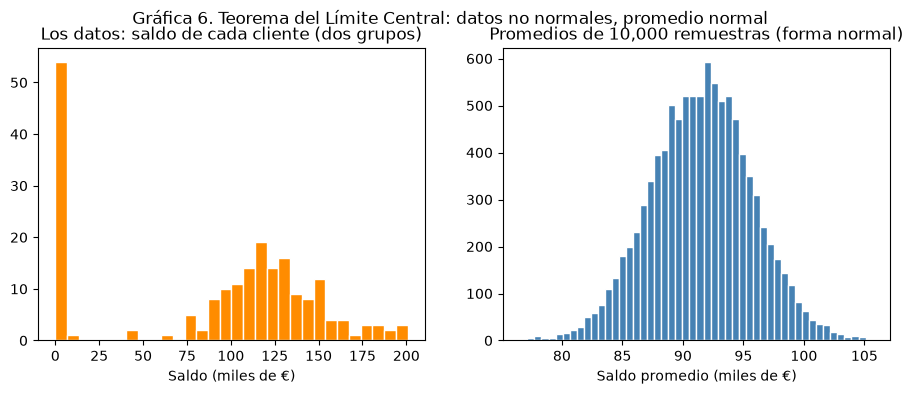

In [15]:
# QUÉ HACE ESTA CELDA: Gráfica 6 del reporte: saldos individuales contra promedios de las remuestras
# crea el lienzo de la gráfica; figsize = (ancho, alto)
plt.figure(figsize=(11, 3.8))

# subplot(1, 2, 1): cuadrícula de 1 fila y 2 columnas; se dibuja en la 1.ª
plt.subplot(1, 2, 1)
# hist dibuja un histograma: barras que cuentan cuántos valores caen en cada rango; bins = número de barras
plt.hist(saldo_abandona / 1000, bins=30, color="darkorange", edgecolor="white")
# textos de los ejes y título de la gráfica
plt.title("Los datos: saldo de cada cliente (dos grupos)")
plt.xlabel("Saldo (miles de €)")

# ahora se dibuja en la 2.ª posición (la de la derecha)
plt.subplot(1, 2, 2)
plt.hist(medias_bootstrap / 1000, bins=50, color="steelblue", edgecolor="white")
plt.title("Promedios de 10,000 remuestras (forma normal)")
plt.xlabel("Saldo promedio (miles de €)")

# título general arriba de las dos gráficas
plt.suptitle("Gráfica 6. Teorema del Límite Central: datos no normales, promedio normal")
# guarda la gráfica como imagen PNG en reports/figures (es la que aparece en el reporte PDF)
plt.savefig("../reports/figures/g6_tlc_bootstrap_saldo.png", bbox_inches="tight")
# muestra la gráfica en pantalla
plt.show()

**Interpretación:** con 95 % de confianza, el saldo promedio de los clientes que abandonan el banco está entre **€83,665 y €99,458**.

**Supuesto de normalidad:** los saldos individuales no son normales (forman dos grupos, gráfica 3). La gráfica de la derecha muestra que los promedios de las remuestras sí tienen forma normal. Por eso la fórmula t es adecuada.

El intervalo es ancho (±€7,897) porque sólo 206 clientes de la muestra abandonaron y los saldos varían mucho ($s$ = €60,593).

### 5.3 Intervalo para una diferencia de proporciones (P3) · inactivos − activos ($p_1 - p_2$)

> 📄 **En el reporte PDF:** sección **5.3**. Resultado: (0.063, 0.159).

$$IC = (\hat p_1 - \hat p_2) \;\pm\; z_{\alpha/2}\sqrt{\frac{\hat p_1(1-\hat p_1)}{n_1} + \frac{\hat p_2(1-\hat p_2)}{n_2}}\cdot \text{FCPF}$$

| Símbolo | ¿Qué es? |
|---|---|
| $\hat p_1$, $n_1$ | Proporción que abandona y tamaño del grupo de **inactivos** |
| $\hat p_2$, $n_2$ | Proporción que abandona y tamaño del grupo de **activos** |
| La raíz | El "brinco" de la diferencia: **se suman los brincos de los dos grupos**, porque los dos tienen azar |

**¿Por qué esta fórmula?** Queremos comparar **dos porcentajes de dos grupos distintos**. Los grupos no se mezclan: cada cliente es activo *o* inactivo, nunca los dos (a eso se le llama grupos **independientes**).

**La clave para leer el resultado: ¿el rango toca el cero?**
- Si el rango **incluye el 0** (por ejemplo, de −2 a +5 puntos), podría ser que los dos grupos se vayan igual.
- Si el rango **no incluye el 0** (por ejemplo, de +6 a +16), hay evidencia de una diferencia real entre todos los clientes.

In [16]:
# QUÉ HACE ESTA CELDA: Supuesto de 5.3: clientes que abandonan y permanecen en cada grupo de actividad
# supuesto: al menos 10 que abandonan y 10 que permanecen en cada grupo
# crosstab arma una tabla de doble entrada: cuenta clientes en cada combinación de fila y columna
pd.crosstab(muestra["miembro_activo"], muestra["abandono"])

abandono,0,1
miembro_activo,,
0,340,123
1,454,83


In [17]:
# QUÉ HACE ESTA CELDA: Intervalo de confianza 95 % para P3 (reporte 5.3)
# len() cuenta cuántos clientes hay en el grupo
n_inactivos = len(abandono_inactivos)
n_activos = len(abandono_activos)
# pieza de la fórmula de cada grupo: p(1 − p) / n
varianza_inactivos = p_inactivos * (1 - p_inactivos) / n_inactivos
varianza_activos = p_activos * (1 - p_activos) / n_activos
# se suman las piezas de los dos grupos y se saca raíz: error estándar de la diferencia
error_estandar_dif_p = np.sqrt(varianza_inactivos + varianza_activos) * fcpf
# margen de error = valor crítico × error estándar
margen_dif_p = z_95 * error_estandar_dif_p
# límite inferior = estimación − margen de error
limite_inf_dif_p = dif_p - margen_dif_p
# límite superior = estimación + margen de error
limite_sup_dif_p = dif_p + margen_dif_p
print("IC 95 % para p1 − p2, límite inferior:", limite_inf_dif_p)
print("IC 95 % para p1 − p2, límite superior:", limite_sup_dif_p)

IC 95 % para p1 − p2, límite inferior: 0.06315619298449143
IC 95 % para p1 − p2, límite superior: 0.15903653439061466


In [18]:
# QUÉ HACE ESTA CELDA: Tamaño del efecto de P3: riesgo relativo
# tamaño del efecto: cuántas veces más abandonan los inactivos
# cuántas veces más abandonan los inactivos que los activos
riesgo_relativo = p_inactivos / p_activos
print("Diferencia (puntos porcentuales):", dif_p * 100)
print("Riesgo relativo (inactivos / activos):", riesgo_relativo)

Diferencia (puntos porcentuales): 11.109636368755304
Riesgo relativo (inactivos / activos): 1.7187800879544095


**Interpretación:** con 95 % de confianza, la tasa de abandono de los clientes **inactivos** es **entre 6.3 y 15.9 puntos porcentuales mayor** que la de los activos, en toda la población.

**¿Contiene el 0?** No. Todo el intervalo es positivo: los datos sólo son compatibles con que los inactivos abandonan más.

**Tamaño del efecto:** en la muestra, los inactivos abandonan 1.72 veces más que los activos (26.6 % contra 15.5 %). Es una diferencia con importancia práctica para el banco: de cada 100 inactivos se van unos 11 clientes más que de cada 100 activos.

⚠️ Este estudio sólo observa a los clientes; no es un experimento. Por eso no demuestra que la inactividad cause el abandono: puede que el cliente deje de usar su cuenta porque ya está pensando en irse. Sí permite usar la inactividad como señal de alerta.

### 5.4 Intervalo para una diferencia de medias (P4) · edad de quien abandona − edad de quien se queda ($\mu_1 - \mu_2$)

> 📄 **En el reporte PDF:** sección **5.4**. Resultado: (8.04, 10.78) años.

$$IC = (\bar x_1 - \bar x_2) \;\pm\; t_{\alpha/2,\,gl}\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}\cdot \text{FCPF}$$

| Símbolo | ¿Qué es? |
|---|---|
| $\bar x_1$, $s_1$, $n_1$ | Edad promedio, desviación estándar y tamaño del grupo que **abandona** |
| $\bar x_2$, $s_2$, $n_2$ | Lo mismo para el grupo que **permanece** |
| $s^2$ | Varianza: la desviación estándar al cuadrado (otra forma de medir qué tan regados están los datos) |
| $gl$ | "Grados de libertad": un ajuste que depende del tamaño de los grupos y decide qué tan ancha es la campana $t$; lo calcula la computadora |

📌 **Decisión: método de Welch.** Hay dos formas de comparar promedios: una supone que los dos grupos están igual de "regados" y otra (la de **Welch**) no lo supone. Elegimos Welch porque **funciona en ambos casos**: si los grupos están igual de regados da casi el mismo resultado, y si no, sigue siendo correcto. Es la opción más segura.

In [19]:
# QUÉ HACE ESTA CELDA: Supuestos de 5.4: tamaño, dispersión y asimetría de la edad en cada grupo
# supuestos: grupos independientes y medias aproximadamente normales (n grandes)
# len() cuenta cuántos clientes hay en el grupo
n_abandona = len(edad_abandona)
n_permanece = len(edad_permanece)
# var() calcula la varianza (la desviación estándar al cuadrado)
varianza_abandona = edad_abandona.var()
varianza_permanece = edad_permanece.var()
print("n abandona:", n_abandona)
print("n permanece:", n_permanece)
print("Desviación estándar, abandona:", np.sqrt(varianza_abandona))
print("Desviación estándar, permanece:", np.sqrt(varianza_permanece))
# asimetría: 0 = simétrico; positivo = cola larga hacia la derecha
print("Asimetría de la edad, abandona:", stats.skew(edad_abandona))
print("Asimetría de la edad, permanece:", stats.skew(edad_permanece))

n abandona: 206
n permanece: 794
Desviación estándar, abandona: 9.23817507731781
Desviación estándar, permanece: 9.93562745768552
Asimetría de la edad, abandona: 0.1566512799608494
Asimetría de la edad, permanece: 1.368020801824045


In [20]:
# QUÉ HACE ESTA CELDA: Intervalo de confianza 95 % para P4 con el método de Welch (reporte 5.4)
# varianza ÷ n de cada grupo (piezas de la fórmula de Welch)
v_abandona = varianza_abandona / n_abandona
v_permanece = varianza_permanece / n_permanece
# grados de libertad de Welch–Satterthwaite
gl = (v_abandona + v_permanece) ** 2 / (v_abandona ** 2 / (n_abandona - 1) + v_permanece ** 2 / (n_permanece - 1))
# t.ppf(0.975, gl) da el valor crítico t para 95 % con esos grados de libertad
t_edad = stats.t.ppf(0.975, gl)
# se suman las piezas de los dos grupos y se saca raíz: error estándar de la diferencia
error_estandar_edad = np.sqrt(v_abandona + v_permanece) * fcpf
# margen de error = valor crítico × error estándar
margen_edad = t_edad * error_estandar_edad
# límite inferior = estimación − margen de error
limite_inf_edad = dif_edad - margen_edad
# límite superior = estimación + margen de error
limite_sup_edad = dif_edad + margen_edad
print("Grados de libertad:", gl)
print("IC 95 % para μ1 − μ2, límite inferior (años):", limite_inf_edad)
print("IC 95 % para μ1 − μ2, límite superior (años):", limite_sup_edad)

Grados de libertad: 338.61935379134474
IC 95 % para μ1 − μ2, límite inferior (años): 8.037039105649463
IC 95 % para μ1 − μ2, límite superior (años): 10.776196080577328


In [21]:
# QUÉ HACE ESTA CELDA: Tamaño del efecto de P4: d de Cohen
# tamaño del efecto: d de Cohen (diferencia en desviaciones estándar)
# junta la variación de los dos grupos
suma_cuadrados = (n_abandona - 1) * varianza_abandona + (n_permanece - 1) * varianza_permanece
# varianza combinada de los dos grupos
varianza_combinada = suma_cuadrados / (n_abandona + n_permanece - 2)
# d = diferencia de medias ÷ desviación estándar combinada
d_cohen = dif_edad / np.sqrt(varianza_combinada)
print("d de Cohen:", d_cohen)

d de Cohen: 0.9602100717259384


**Supuestos:** los grupos son independientes (cada cliente abandona o permanece). La edad de quienes permanecen tiene asimetría de 1.37 (sesgo a la derecha). Con 794 clientes en ese grupo y 206 en el otro, el Teorema del Límite Central permite usar la distribución t para la diferencia de medias. El método de Welch no supone varianzas iguales.

**Interpretación:** con 95 % de confianza, la edad promedio de los clientes que abandonan es **entre 8.0 y 10.8 años mayor** que la de quienes permanecen. El intervalo no contiene el 0.

**Tamaño del efecto:** d de Cohen = 0.96. Según la referencia de Cohen (0.2 pequeño, 0.5 mediano, 0.8 grande), es un efecto grande.

Es una asociación, no una causa: la edad puede relacionarse con otros factores (necesidades financieras distintas, ofertas de la competencia).

#### Resumen de los cuatro intervalos

> 📄 **En el reporte PDF:** **Tabla 9** (resumen de intervalos de confianza al 95 %).

In [22]:
# QUÉ HACE ESTA CELDA: Tabla 9 del reporte: resumen de los 4 intervalos
# arma la tabla resumen de los 4 intervalos
resumen_ic = pd.DataFrame({
    "Estimación puntual": [p_hat, media_saldo, dif_p, dif_edad],
    "Límite inferior": [limite_inf_p, limite_inf_saldo, limite_inf_dif_p, limite_inf_edad],
    "Límite superior": [limite_sup_p, limite_sup_saldo, limite_sup_dif_p, limite_sup_edad],
}, index=["P1: p", "P2: μ saldo (€)", "P3: p₁ − p₂", "P4: μ₁ − μ₂ edad (años)"])
# escribir el nombre de una tabla en la última línea la muestra en pantalla
resumen_ic

,Estimación puntual,Límite inferior,Límite superior
P1: p,0.206000,0.182219,0.229781
P2: μ saldo (€),91561.533058,83664.739574,99458.326542
P3: p₁ − p₂,0.111096,0.063156,0.159037
P4: μ₁ − μ₂ edad (años),9.406618,8.037039,10.776196


---
## 6. Análisis e interpretación

> 📄 **En el reporte PDF:** sección **6**.

### 6.1 ¿Qué significa cada intervalo?

> 📄 **En el reporte PDF:** sección **6.1**.

La interpretación de cada intervalo está escrita al final de las secciones 5.1, 5.2, 5.3 y 5.4. Las ideas que pide el reporte son:

- **P1:** entre 18.2 % y 23.0 % de los clientes abandona (entre unos 1,820 y 2,300 de los 10,000).
- **P2:** el saldo promedio de quien abandona está entre €83,665 y €99,458.
- **P3:** los inactivos abandonan entre 6.3 y 15.9 puntos porcentuales más. El intervalo no contiene el 0. Es una asociación, no una causa.
- **P4:** quienes abandonan son entre 8.0 y 10.8 años mayores. El intervalo no contiene el 0.
- **El 95 %** describe al método: 95 de cada 100 intervalos construidos así contienen el valor real. No es la probabilidad de que el valor real esté en este intervalo.

| Pregunta | Respuesta |
|---|---|
| **¿Qué significa el intervalo?** | Un rango de valores **plausibles** para un número de **toda la población**, construido con un método que acierta el 95 % de las veces. |
| **¿Qué parámetro se estima?** | P1: $p$, la proporción de abandono; P2: $\mu$, el saldo promedio de quien abandona; P3: $p_1 - p_2$, cuánto más abandonan los inactivos; P4: $\mu_1 - \mu_2$, la diferencia de edad promedio. |
| **¿Qué nivel de confianza?** | 95 %. |
| **¿Por qué ese nivel?** | Es el estándar que equilibra precisión y confiabilidad; los errores en esta decisión son económicos y corregibles. |
| **¿Qué pasa si aumenta n?** | El intervalo se **estrecha** (sección 6.3); el nivel de confianza no cambia. |
| **¿Qué pasa con 99 %?** | El intervalo se vuelve **más amplio** (≈ 31 % más; sección 6.2). |
| **¿Más amplio o más estrecho?** | Más **amplio** con 99 %; más **estrecho** con 90 % o con más muestra. |
| **¿Limitaciones?** | Ver 6.5. |

### 6.2 Nivel de confianza: ¿por qué 95 % y qué pasaría con 99 %?

> 📄 **En el reporte PDF:** sección **6.2** y **Gráfica 7**.

Sólo cambia el valor crítico: 1.645 (90 %), 1.96 (95 %) o 2.576 (99 %). Más confianza → valor crítico más grande → **intervalo más ancho**. Se repite el intervalo 1 (proporción de abandono) con los tres niveles.

In [23]:
# QUÉ HACE ESTA CELDA: Reporte 6.2: intervalo de P1 con 90 %, 95 % y 99 % de confianza
# valor crítico para 90 % de confianza: 1.645
z_90 = stats.norm.ppf(0.95)
# valor crítico para 99 % de confianza: 2.576
z_99 = stats.norm.ppf(0.995)
# margen de error = valor crítico × error estándar
margen_90 = z_90 * error_estandar_p
margen_99 = z_99 * error_estandar_p

print("IC 90 %:", p_hat - margen_90, p_hat + margen_90)
print("IC 95 %:", p_hat - margen_p, p_hat + margen_p)
print("IC 99 %:", p_hat - margen_99, p_hat + margen_99)

IC 90 %: 0.1860421346278687 0.22595786537213128
IC 95 %: 0.1822187366117347 0.22978126338826527
IC 99 %: 0.17474612207464443 0.23725387792535554


In [24]:
# QUÉ HACE ESTA CELDA: Cuánto más ancho o más estrecho es cada intervalo comparado con el de 95 %
# el ancho es proporcional al valor crítico
print("Ancho del IC 90 % comparado con el de 95 %:", z_90 / z_95)
print("Ancho del IC 99 % comparado con el de 95 %:", z_99 / z_95)

Ancho del IC 90 % comparado con el de 95 %: 0.8392264551419658
Ancho del IC 99 % comparado con el de 95 %: 1.3142227734115084


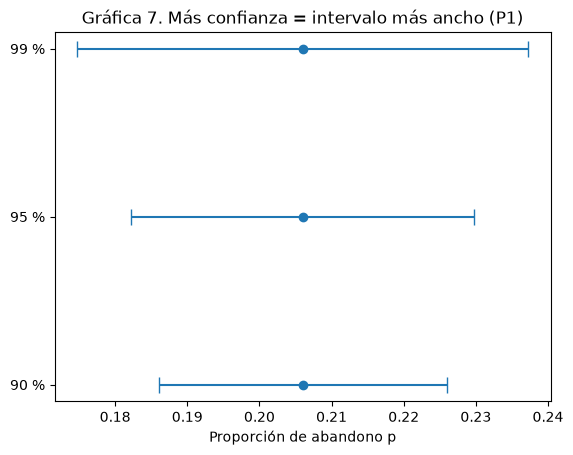

In [25]:
# QUÉ HACE ESTA CELDA: Gráfica 7 del reporte: los tres intervalos de P1
# lista con los tres márgenes de error
margenes = [margen_90, margen_p, margen_99]
# errorbar dibuja un punto (p̂) con una línea que va del límite inferior al superior
plt.errorbar([p_hat, p_hat, p_hat], [0, 1, 2], xerr=margenes, fmt="o", capsize=6)
# textos de los ejes y título de la gráfica
plt.yticks([0, 1, 2], ["90 %", "95 %", "99 %"])
plt.xlabel("Proporción de abandono p")
plt.title("Gráfica 7. Más confianza = intervalo más ancho (P1)")
# guarda la gráfica como imagen PNG en reports/figures (es la que aparece en el reporte PDF)
plt.savefig("../reports/figures/g7_niveles_confianza.png", bbox_inches="tight")
# muestra la gráfica en pantalla
plt.show()

**Interpretación:** con **99 %** el intervalo es **31 % más ancho** que con 95 % (2.576 / 1.96 = 1.31); con **90 %** es **16 % más estrecho** (1.645 / 1.96 = 0.84). Lo mismo pasa con los otros tres intervalos, porque su ancho también es proporcional al valor crítico (en los de t la proporción es casi igual). Con los mismos datos no se puede ganar confianza y precisión a la vez; la única forma de ganar precisión sin perder confianza es **aumentar la muestra**.

### 6.3 ¿Qué sucede si aumenta el tamaño de muestra?

> 📄 **En el reporte PDF:** sección **6.3** y **Gráfica 8**.


Más clientes revisados → error estándar más chico → **intervalo más angosto**. Como el tamaño de la muestra está dentro de una raíz cuadrada, **para reducir el margen a la mitad hay que revisar 4 veces más clientes**. Si se revisara a todos (n = 10,000), el margen sería **cero**.

In [26]:
# QUÉ HACE ESTA CELDA: Reporte 6.3: margen de error de P1 para distintos tamaños de muestra
# varios tamaños de muestra para comparar
tamanos = np.array([100, 250, 500, 1000, 2000, 4000, 8000])
# FCPF de cada tamaño: se hace más chico mientras más grande es n
fcpf_tamanos = np.sqrt((N - tamanos) / (N - 1))
# margen de error de P1 para cada tamaño de muestra
margenes_tamanos = 1.96 * np.sqrt(p_hat * (1 - p_hat) / tamanos) * fcpf_tamanos
# tabla con el margen de error para cada tamaño de muestra
tabla_tamanos = pd.DataFrame({"n": tamanos,
                              "% de la población": tamanos / N * 100,
                              "Margen de error (± puntos %)": margenes_tamanos * 100})
# escribir el nombre de una tabla en la última línea la muestra en pantalla
tabla_tamanos

,n,% de la población,Margen de error (± puntos %)
0,100,1.0,7.887498
1,250,2.5,4.950556
2,500,5.0,3.455401
3,1000,10.0,2.378170
4,2000,20.0,1.585447
5,4000,40.0,0.970884
6,8000,80.0,0.396362


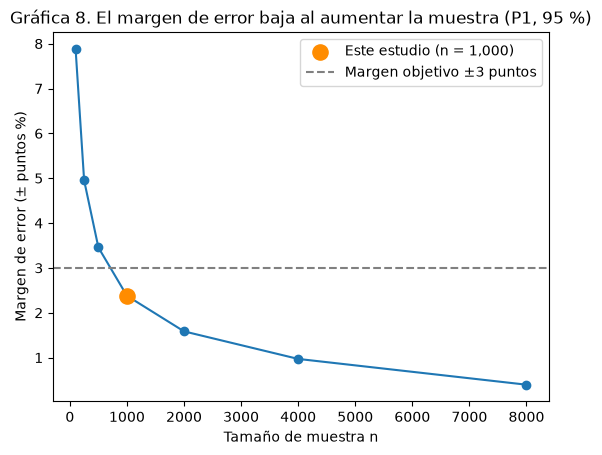

In [27]:
# QUÉ HACE ESTA CELDA: Gráfica 8 del reporte: margen de error contra tamaño de muestra
# plot dibuja una línea que une los puntos
plt.plot(tamanos, margenes_tamanos * 100, "o-")
# scatter dibuja un punto; aquí marca nuestro estudio
plt.scatter([n], [margen_p * 100], s=120, color="darkorange", zorder=3, label="Este estudio (n = 1,000)")
# axhline dibuja una línea horizontal en ese valor
plt.axhline(3, linestyle="--", color="gray", label="Margen objetivo ±3 puntos")
# textos de los ejes y título de la gráfica
plt.xlabel("Tamaño de muestra n")
plt.ylabel("Margen de error (± puntos %)")
plt.title("Gráfica 8. El margen de error baja al aumentar la muestra (P1, 95 %)")
# muestra el cuadro que explica cada línea o color
plt.legend()
# guarda la gráfica como imagen PNG en reports/figures (es la que aparece en el reporte PDF)
plt.savefig("../reports/figures/g8_margen_vs_n.png", bbox_inches="tight")
# muestra la gráfica en pantalla
plt.show()

**Interpretación:** con n = 1,000 el margen obtenido (≈ ±2.4 puntos) es **mejor que el objetivo de ±3 puntos**, porque el tamaño se calculó con el caso más conservador $p$ = 0.5 y la proporción real de la muestra (≈ 0.21) tiene menos variabilidad. Duplicar la muestra a 2,000 sólo bajaría el margen a ≈ ±1.6 puntos, a cambio del doble de expedientes revisados.

### 6.4 Comprobación con la población completa

> 📄 **En el reporte PDF:** sección **6.4** y **Gráfica 9**. El reporte escribe "942 de 1,000 (94.2 %)"; este cuaderno da **946 de 1,000 (94.6 %)** porque la simulación se reprogramó con otro sorteo. Los dos están cerca del 95 % y la conclusión es la misma.

#### a) Simulación: ¿qué significa realmente "95 %"?

Como se tiene a la población completa, se puede hacer algo que en la vida real es imposible: **tomar 1,000 muestras distintas**, construir un IC de 95 % con cada una y **contar cuántos atrapan la verdadera $p$**.

In [28]:
# QUÉ HACE ESTA CELDA: Reporte 6.4: lee la población completa (sólo para comprobar, nunca para estimar)
# la población sólo se usa aquí, después de estimar, para comprobar el método
# read_csv lee el archivo CSV y lo guarda como tabla
poblacion = pd.read_csv("../data/processed/poblacion_clientes.csv")
# proporción real en los 10,000 clientes (sólo para comprobar)
p_real = poblacion["abandono"].mean()
print("Proporción real en la población:", p_real)

Proporción real en la población: 0.2037


In [29]:
# QUÉ HACE ESTA CELDA: Simula 1,000 muestras y cuenta cuántos intervalos contienen la p real
# 1,000 copias de la población; cada fila se baraja y se toman 1,000 clientes (sin reemplazo)
# crea un generador de números al azar; el número entre paréntesis es la semilla
generador = np.random.default_rng(123)
# np.tile repite la lista de clientes, una copia por fila
copias = np.tile(poblacion["abandono"].to_numpy(), (1000, 1))
# permuted revuelve al azar el orden de los clientes dentro de cada fila
barajadas = generador.permuted(copias, axis=1)
# toma las primeras columnas de cada fila: una muestra sin clientes repetidos
muestras_simuladas = barajadas[:, :n]
# mean(axis=1) saca el promedio de cada fila: un resultado por muestra
p_simuladas = muestras_simuladas.mean(axis=1)

# margen de error de cada una de las 1,000 muestras simuladas
margenes_simulados = z_95 * np.sqrt(p_simuladas * (1 - p_simuladas) / n) * fcpf
# límites inferiores de los 1,000 intervalos
inferiores = p_simuladas - margenes_simulados
# límites superiores de los 1,000 intervalos
superiores = p_simuladas + margenes_simulados

# True si el intervalo contiene a la p real (& significa "y")
contiene = (inferiores <= p_real) & (p_real <= superiores)
print("Intervalos que contienen a p:", contiene.sum())
# el promedio de una columna de 0 y 1 (o True y False) es la proporción; × 100 da el porcentaje
print("% de intervalos que contienen a p:", contiene.mean() * 100)

Intervalos que contienen a p: 946
% de intervalos que contienen a p: 94.6


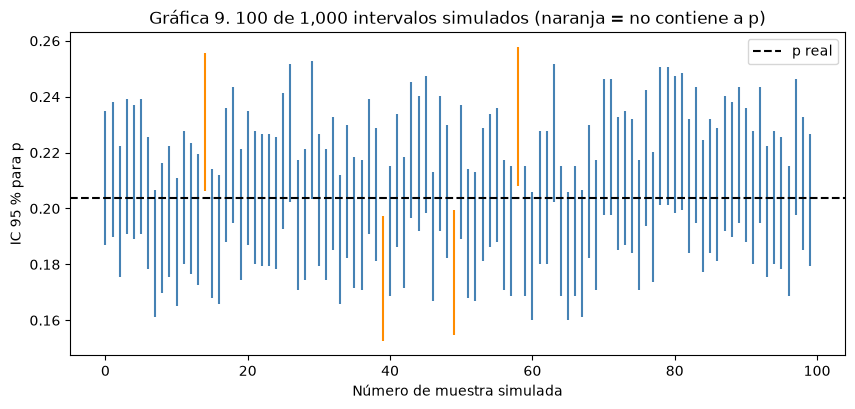

In [30]:
# QUÉ HACE ESTA CELDA: Gráfica 9 del reporte: los primeros 100 intervalos simulados
# se dibujan los primeros 100 (naranja = no contiene a p)
# np.where: azul si el intervalo contiene a p, naranja si no; [:100] = los primeros 100
colores = np.where(contiene[:100], "steelblue", "darkorange")
# crea el lienzo de la gráfica; figsize = (ancho, alto)
plt.figure(figsize=(10, 4.2))
# vlines dibuja una línea vertical por intervalo, del límite inferior al superior
plt.vlines(range(100), inferiores[:100], superiores[:100], colors=colores)
# axhline dibuja una línea horizontal en ese valor
plt.axhline(p_real, color="black", linestyle="--", label="p real")
# textos de los ejes y título de la gráfica
plt.xlabel("Número de muestra simulada")
plt.ylabel("IC 95 % para p")
plt.title("Gráfica 9. 100 de 1,000 intervalos simulados (naranja = no contiene a p)")
# muestra el cuadro que explica cada línea o color
plt.legend(loc="upper right")
# guarda la gráfica como imagen PNG en reports/figures (es la que aparece en el reporte PDF)
plt.savefig("../reports/figures/g9_simulacion_cobertura.png", bbox_inches="tight")
# muestra la gráfica en pantalla
plt.show()

**Interpretación:** aproximadamente **95 de cada 100 intervalos atrapan la verdadera $p$**, y unos 5 fallan (en naranja). Eso es exactamente lo que significa "95 % de confianza": la **tasa de acierto del método**. Con una sola muestra (la del estudio) nunca se sabe si se cayó entre los aciertos o los fallos; por eso se habla de *confianza* y no de *certeza*.

#### b) Validación: ¿los intervalos del estudio atraparon los valores reales?

In [31]:
# QUÉ HACE ESTA CELDA: Compara cada intervalo del estudio con el valor real de la población
# los mismos grupos, ahora en la población completa
abandona_pob = poblacion["abandono"] == 1
permanece_pob = poblacion["abandono"] == 0
inactivo_pob = poblacion["miembro_activo"] == 0
activo_pob = poblacion["miembro_activo"] == 1

# loc[filas, columna]: toma esa columna sólo de las filas marcadas con True
saldo_real = poblacion.loc[abandona_pob, "saldo"].mean()
dif_p_real = poblacion.loc[inactivo_pob, "abandono"].mean() - poblacion.loc[activo_pob, "abandono"].mean()
dif_edad_real = poblacion.loc[abandona_pob, "edad"].mean() - poblacion.loc[permanece_pob, "edad"].mean()

# agrega una columna nueva a la tabla resumen con los valores reales
resumen_ic["Valor real"] = [p_real, saldo_real, dif_p_real, dif_edad_real]
# True si el valor real no queda por debajo del límite inferior
arriba_del_inferior = resumen_ic["Límite inferior"] <= resumen_ic["Valor real"]
# True si el valor real no queda por encima del límite superior
abajo_del_superior = resumen_ic["Valor real"] <= resumen_ic["Límite superior"]
# el intervalo acierta si cumple las dos condiciones
resumen_ic["¿El IC lo contiene?"] = arriba_del_inferior & abajo_del_superior
# escribir el nombre de una tabla en la última línea la muestra en pantalla
resumen_ic

,Estimación puntual,Límite inferior,Límite superior,Valor real,¿El IC lo contiene?
P1: p,0.206000,0.182219,0.229781,0.203700,True
P2: μ saldo (€),91561.533058,83664.739574,99458.326542,91108.539337,True
P3: p₁ − p₂,0.111096,0.063156,0.159037,0.125818,True
P4: μ₁ − μ₂ edad (años),9.406618,8.037039,10.776196,7.429608,False


In [32]:
# QUÉ HACE ESTA CELDA: Cuenta cuántos intervalos acertaron
print("Intervalos que contienen el valor real:", resumen_ic["¿El IC lo contiene?"].sum(), "de 4")

Intervalos que contienen el valor real: 3 de 4


**Interpretación:** **3 de los 4 intervalos** contienen el valor real de la población usando sólo el 10 % de los clientes. El intervalo de la edad (P4) no lo contiene: el valor real es 7.4 años y el intervalo va de 8.0 a 10.8.

Las estimaciones puntuales no coinciden exactamente con los valores reales; esa diferencia es el **error de muestreo**. Que un intervalo falle es esperable: con 95 % de confianza, aproximadamente 1 de cada 20 intervalos no contiene su parámetro.

### 6.5 Limitaciones

> 📄 **En el reporte PDF:** sección **6.5**.

1. **Origen del dataset:** el banco no está identificado y no hay fechas; las conclusiones aplican a **esta cartera**, no a toda la banca europea.
2. **Sólo error aleatorio:** el IC no cubre errores de registro (por ejemplo, si algún "abandono" estuviera mal capturado).
3. **Sólo se observó, no se experimentó:** P3 y P4 muestran cosas que **ocurren juntas**, no que una **provoque** la otra.
4. **Las fórmulas suponen la "campana":** eso funciona con muestras grandes como la nuestra, y se comprobó con el remuestreo (bootstrap) y la simulación.
5. **Varios rangos a la vez:** cada rango acierta el 95 % de las veces, pero que **los cuatro** acierten al mismo tiempo es menos seguro (al menos 80 %). De hecho, en la validación uno de los cuatro falló.

---
## 7. Teoría de decisión

> 📄 **En el reporte PDF:** sección **7**. En el reporte no tiene subsecciones numeradas; aquí 7.1 a 7.7 siguen el mismo orden: decisión y supuestos → Tabla 10 → Tabla 11 y criterios → sensibilidad (Gráfica 10) → costo de equivocarse → recomendación.


### 7.1 La decisión

> *"Si fuéramos responsables del área de Retención del banco, ¿a quién dirigiríamos una campaña de retención?"*

**Opciones:**
- **A1 —** No hacer campaña.
- **A2 —** Campaña **sólo a clientes inactivos**.
- **A3 —** Campaña a **todos** los clientes.

La campaña es una llamada de un asesor más una bonificación al cliente.

### 7.2 Supuestos económicos (valores ilustrativos en euros)

| Símbolo | ¿Qué es? | Valor | Origen |
|---|---|---|---|
| $c$ | Costo de contactar a un cliente | €25 | Llamada + bonificación |
| $e$ | **Efectividad**: de cada 100 clientes que *iban* a irse, cuántos se logran retener | 25 % | **Supuesto** (no viene de los datos) |
| $V$ | Valor de retener a un cliente (ganancia anual que deja) | €500 | Margen por depósitos y comisiones |

**Beneficio esperado por cliente contactado:**

$$B = p \cdot e \cdot V - c$$

*En palabras:* de cada cliente contactado, con probabilidad $p$ se iba a ir; de esos, se retiene una fracción $e$; cada retenido vale $V$; y contactarlo cuesta $c$ siempre.

La campaña **conviene** cuando $B > 0$, es decir, cuando la tasa de abandono del grupo supera el **umbral de equilibrio**:

$$p^* = \frac{c}{e \cdot V} = \frac{25}{0.25 \times 500} = 0.20$$

**Regla de decisión:** usar el **intervalo de confianza completo**, no sólo la estimación puntual. Si **todo** el IC de un grupo está por encima de 0.20, la campaña conviene aun en el peor caso razonable.

In [33]:
# QUÉ HACE ESTA CELDA: Supuestos económicos y umbral de rentabilidad p*
costo = 25
efectividad = 0.25
valor_cliente = 500
# umbral p* = c / (e · V): tasa de abandono a partir de la cual la campaña gana dinero
p_umbral = costo / (efectividad * valor_cliente)
print("Umbral de equilibrio p*:", p_umbral)

Umbral de equilibrio p*: 0.2


#### Intervalo de la tasa de abandono de cada grupo

> 📄 **En el reporte PDF:** **Tabla 10** (tasa de abandono por grupo frente al umbral). El reporte escribe 0.228 como límite inferior de los inactivos; el valor exacto es 0.22749, que redondea a **0.227**.

In [34]:
# QUÉ HACE ESTA CELDA: Tabla 10 del reporte: intervalo de abandono de inactivos y activos, comparado con p*
# IC 95 % de la tasa de abandono de cada grupo
# error estándar de la proporción de abandono de cada grupo
error_estandar_inactivos = np.sqrt(p_inactivos * (1 - p_inactivos) / n_inactivos) * fcpf
error_estandar_activos = np.sqrt(p_activos * (1 - p_activos) / n_activos) * fcpf
# límite inferior = estimación − margen de error
limite_inf_inactivos = p_inactivos - z_95 * error_estandar_inactivos
# límite superior = estimación + margen de error
limite_sup_inactivos = p_inactivos + z_95 * error_estandar_inactivos
limite_inf_activos = p_activos - z_95 * error_estandar_activos
limite_sup_activos = p_activos + z_95 * error_estandar_activos

print("Inactivos, IC 95 %:", limite_inf_inactivos, limite_sup_inactivos)
print("Activos, IC 95 %:", limite_inf_activos, limite_sup_activos)
print("¿Todo el IC de inactivos está arriba de p*?:", limite_inf_inactivos > p_umbral)
print("¿Todo el IC de activos está abajo de p*?:", limite_sup_activos < p_umbral)

Inactivos, IC 95 %: 0.22748967634300146 0.3038278182574305
Activos, IC 95 %: 0.12555579833790492 0.18356896888742097
¿Todo el IC de inactivos está arriba de p*?: True
¿Todo el IC de activos está abajo de p*?: True


In [35]:
# QUÉ HACE ESTA CELDA: Número estimado de clientes inactivos y activos en la población
# clientes de cada grupo en la población (misma proporción que en la muestra)
clientes_inactivos = N * n_inactivos / n
clientes_activos = N - clientes_inactivos
print("Clientes inactivos estimados:", clientes_inactivos)
print("Clientes activos estimados:", clientes_activos)

Clientes inactivos estimados: 4630.0
Clientes activos estimados: 5370.0


### 7.3 Matriz de decisión

> 📄 **En el reporte PDF:** **Tabla 11** (beneficio neto total esperado) y el párrafo de los tres criterios.


Como no sabemos el porcentaje exacto, cada opción se prueba en tres **escenarios** sacados del rango: **pesimista** (el extremo bajo del rango), **puntual** (el valor del centro) y **optimista** (el extremo alto). Así la duda del muestreo **entra en la decisión** en lugar de ignorarse.

Para elegir se usan tres formas de pensar (**criterios de decisión**). Si las tres coinciden, la decisión es sólida:
- **Valor esperado** (el optimista razonable): ¿qué opción gana más **si todo sale como lo estimamos**?
- **Mejor peor caso** (el precavido; en inglés *maximin*): ¿qué opción deja el mejor resultado **aun si todo sale mal**?
- **Mínimo arrepentimiento** (el que odia lamentarse): ¿con qué opción **me arrepentiría menos** al enterarme después de cuál era la mejor?

In [36]:
# QUÉ HACE ESTA CELDA: Tabla 11 del reporte: beneficio de cada opción en los tres escenarios
# beneficio neto total B = p·e·V − c por cliente, en tres escenarios: pesimista, puntual y optimista
# tres escenarios: límite inferior (pesimista), p̂ (puntual) y límite superior (optimista)
p_escenarios_inactivos = np.array([limite_inf_inactivos, p_inactivos, limite_sup_inactivos])
p_escenarios_activos = np.array([limite_inf_activos, p_activos, limite_sup_activos])
# beneficio total = (p · e · V − c) × número de clientes del grupo
beneficio_inactivos = (p_escenarios_inactivos * efectividad * valor_cliente - costo) * clientes_inactivos
beneficio_activos = (p_escenarios_activos * efectividad * valor_cliente - costo) * clientes_activos

# matriz de decisión: una fila por opción y una columna por escenario
matriz = pd.DataFrame([[0, 0, 0], beneficio_inactivos, beneficio_inactivos + beneficio_activos],
                      index=["A1 · No hacer campaña", "A2 · Sólo inactivos", "A3 · Todos los clientes"],
                      columns=["Pesimista", "Puntual", "Optimista"])
# escribir el nombre de una tabla en la última línea la muestra en pantalla
matriz

,Pesimista,Puntual,Optimista
A1 · No hacer campaña,0.000000,0.0,0.000000
A2 · Sólo inactivos,15909.650184,38000.0,60090.349816
A3 · Todos los clientes,-34061.020182,7500.0,49061.020182


In [37]:
# QUÉ HACE ESTA CELDA: Criterio del mejor peor caso (maximin)
# maximin: el peor resultado de cada opción
# min(axis=1): el resultado más bajo de cada fila (de cada opción)
peor_caso = matriz.min(axis=1)
print("Peor caso de cada opción (€):")
print(peor_caso)

Peor caso de cada opción (€):
A1 · No hacer campaña          0.000000
A2 · Sólo inactivos        15909.650184
A3 · Todos los clientes   -34061.020182
dtype: float64


In [38]:
# QUÉ HACE ESTA CELDA: Criterio de mínimo arrepentimiento: tabla de arrepentimiento
# arrepentimiento: lo que se deja de ganar frente a la mejor opción de cada escenario
# max() de cada columna = lo mejor que se podía ganar en ese escenario; se le resta lo que da cada opción
arrepentimiento = matriz.max() - matriz
# escribir el nombre de una tabla en la última línea la muestra en pantalla
arrepentimiento

,Pesimista,Puntual,Optimista
A1 · No hacer campaña,15909.650184,38000.0,60090.349816
A2 · Sólo inactivos,0.000000,0.0,0.000000
A3 · Todos los clientes,49970.670366,30500.0,11029.329634


In [39]:
# QUÉ HACE ESTA CELDA: Máximo arrepentimiento de cada opción
# el arrepentimiento más grande de cada opción; se elige la opción con el menor
maximo_arrepentimiento = arrepentimiento.max(axis=1)
print("Máximo arrepentimiento de cada opción (€):")
print(maximo_arrepentimiento)

Máximo arrepentimiento de cada opción (€):
A1 · No hacer campaña      60090.349816
A2 · Sólo inactivos            0.000000
A3 · Todos los clientes    49970.670366
dtype: float64


**Lectura de la matriz:**
- **Valor esperado:** la mejor opción es **A2 · Sólo inactivos**.
- **Maximin:** **A2 · Sólo inactivos**.
- **Mínimo arrepentimiento:** **A2 · Sólo inactivos**.

Para los inactivos, el IC (0.227, 0.304) está completo por encima del umbral 0.20. Para los activos, el IC (0.126, 0.184) está completo por debajo del umbral: contactarlos pierde dinero en los tres escenarios.

### 7.4 Análisis de sensibilidad: ¿y si la campaña funciona peor de lo supuesto?

> 📄 **En el reporte PDF:** párrafo «Sensibilidad» y **Gráfica 10**.


La efectividad $e$ = 25 % es el supuesto **más débil**, porque no viene de los datos. Se calcula a partir de qué efectividad cambiaría la decisión.

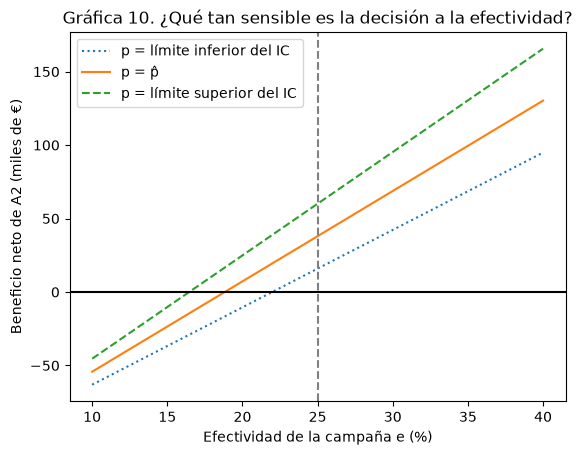

In [40]:
# QUÉ HACE ESTA CELDA: Gráfica 10 del reporte: beneficio de A2 según la efectividad de la campaña
# linspace: 61 valores de efectividad, de 10 % a 40 %
efectividades = np.linspace(0.10, 0.40, 61)
# beneficio de A2 en miles de € para cada efectividad (una línea por escenario)
beneficio_inferior = (limite_inf_inactivos * efectividades * valor_cliente - costo) * clientes_inactivos / 1000
beneficio_puntual = (p_inactivos * efectividades * valor_cliente - costo) * clientes_inactivos / 1000
beneficio_superior = (limite_sup_inactivos * efectividades * valor_cliente - costo) * clientes_inactivos / 1000

# plot dibuja una línea que une los puntos
plt.plot(efectividades * 100, beneficio_inferior, ":", label="p = límite inferior del IC")
plt.plot(efectividades * 100, beneficio_puntual, "-", label="p = p̂")
plt.plot(efectividades * 100, beneficio_superior, "--", label="p = límite superior del IC")
# axhline dibuja una línea horizontal en ese valor
plt.axhline(0, color="black")
# axvline dibuja una línea vertical en ese valor
plt.axvline(25, color="gray", linestyle="--")
# textos de los ejes y título de la gráfica
plt.xlabel("Efectividad de la campaña e (%)")
plt.ylabel("Beneficio neto de A2 (miles de €)")
plt.title("Gráfica 10. ¿Qué tan sensible es la decisión a la efectividad?")
# muestra el cuadro que explica cada línea o color
plt.legend()
# guarda la gráfica como imagen PNG en reports/figures (es la que aparece en el reporte PDF)
plt.savefig("../reports/figures/g10_sensibilidad_efectividad.png", bbox_inches="tight")
# muestra la gráfica en pantalla
plt.show()

In [41]:
# QUÉ HACE ESTA CELDA: Efectividad mínima para que A2 no pierda dinero
# efectividad mínima para que A2 no pierda dinero en el escenario pesimista
# despeja e de p · e · V − c = 0, usando el escenario pesimista
efectividad_minima = costo / (limite_inf_inactivos * valor_cliente)
print("Efectividad mínima (%):", efectividad_minima * 100)

Efectividad mínima (%): 21.979019357613243


**Interpretación:** la campaña a inactivos gana dinero en todo el intervalo de confianza sólo si la efectividad es de al menos **22.0 %**. El supuesto (25 %) está 3 puntos por encima. La decisión no cambia por la incertidumbre del muestreo, pero sí cambiaría si la campaña funcionara peor de lo supuesto.

### 7.5 ¿Cuánto dinero está en juego?

> 📄 **En el reporte PDF:** párrafo «Costo de equivocarse» ("entre €152 y €229 millones").


Depósitos que se llevan los clientes que abandonan ≈ $N \times p \times \mu_{saldo}$. Se usan los límites de los intervalos 1 y 2 como un **rango aproximado** (no es un intervalo de confianza formal).

In [42]:
# QUÉ HACE ESTA CELDA: Dinero en juego: depósitos que se llevan quienes abandonan (millones de €)
# depósitos que se llevan los clientes que abandonan, en millones de €
print("Inferior:", N * limite_inf_p * limite_inf_saldo / 1000000)
print("Puntual:", N * p_hat * media_saldo / 1000000)
print("Superior:", N * limite_sup_p * limite_sup_saldo / 1000000)

Inferior: 152.4528314412531
Puntual: 188.6167581
Superior: 228.53659927417857


### 7.6 Consecuencias de equivocarse

> 📄 **En el reporte PDF:** párrafo «Costo de equivocarse».


| Error posible | ¿Cuándo pasa? | Consecuencia |
|---|---|---|
| **Lanzar la campaña y que no convenga** | La tasa real de los inactivos es menor a 0.20, o la campaña funciona peor de lo supuesto | Se pierde parte del costo de la campaña (≈ €25 × 4,600 inactivos ≈ €116 mil). Pérdida **acotada** y que se detecta rápido. |
| **No lanzarla cuando sí convenía** | La campaña era rentable pero se decidió esperar | Se pierden €500 al año por cada cliente que se pudo retener, y además se van sus depósitos: en total, los clientes que abandonan se llevan entre €150 y €230 millones (sección 7.5). Un cliente que se fue **rara vez regresa**. |

Como **no actuar** es el error más caro y menos reversible, esta asimetría **refuerza** la recomendación de actuar.

### 7.7 Recomendación

> 📄 **En el reporte PDF:** párrafo «Recomendación».


1. **Lanzar la campaña de retención sólo para clientes inactivos (A2).** Es la mejor opción con los tres criterios.
2. **No incluir a los clientes activos:** su tasa de abandono está, con 95 % de confianza, por debajo del umbral de rentabilidad.
3. **Empezar con un piloto con grupo de control:** por ejemplo, 500 inactivos con campaña y 500 sin campaña, elegidos al azar. Así se **mide la efectividad real** (con su propio intervalo de confianza para una diferencia de proporciones) antes de invertir en toda la cartera.
4. **Investigar el caso de Alemania** (gráfica 5), donde la tasa de abandono observada es unos 10 puntos porcentuales mayor que en Francia y España.

> Esta recomendación **no** dice que los clientes se van *porque* son inactivos. Dice que la inactividad **identifica a un grupo** donde, con 95 % de confianza, el abandono es lo bastante alto como para que la campaña sea rentable.

---
## 8. Decisiones metodológicas

> 📄 **En el reporte PDF:** sección **8**. El documento del proyecto pide responderlas **con sus propias palabras**: usen estas respuestas como base.


**1. ¿Por qué se seleccionó esa población?**
Porque la decisión que se quiere apoyar (una campaña de retención) aplica a **toda la cartera de clientes** del banco. El dataset incluye a los 10,000 clientes de Francia, Alemania y España, todos mayores de edad y con su estatus de abandono registrado.

**2. ¿Por qué se usó ese tamaño de muestra?**
La fórmula para estimar una proporción con 95 % de confianza, un margen de ±3 puntos porcentuales y el caso más conservador ($p$ = 0.5) pide ≈ 965 clientes (con corrección por población finita). Se tomaron 1,000 para tener un número redondo y un colchón para los subgrupos. Revisar más expedientes cuesta más y mejora poco la precisión (sección 6.3).

**3. ¿Cómo se seleccionaron los participantes?**
Por **muestreo aleatorio simple sin reemplazo**, con una semilla fija (2026) para que cualquiera pueda reproducir la misma muestra. Se comprobó con pruebas χ² que la muestra se parece a la población.

**4. ¿Por qué se usaron esas técnicas estadísticas?**
Cada técnica corresponde al tipo de pregunta: un **porcentaje** para algo de sí/no (¿se fue?); un **promedio con la campana t** para un número como el saldo (porque no conocemos qué tan regados están los saldos de todos los clientes); una **resta de porcentajes** para comparar dos grupos; y una **resta de promedios con el método de Welch** para comparar edades sin suponer que los dos grupos estén igual de regados. El remuestreo (bootstrap) sólo se usó para comprobar el rango del saldo.

**5. ¿Por qué 95 % de confianza?**
Equilibra precisión y confiabilidad. Los errores de esta decisión son económicos y corregibles, por lo que 99 % haría los intervalos 31 % más anchos sin necesidad; 90 % sería poco exigente para decisiones con dinero de por medio.

**6. ¿Qué supuestos se consideraron?**
Que la muestra se sorteó y cada cliente cuenta una sola vez; que la muestra es lo bastante grande para que se forme la "campana" (al menos 10 casos de cada tipo; Teorema del Límite Central para los promedios, comprobado con remuestreo); que los datos del archivo son correctos; y, en la decisión, que el costo, la efectividad y el valor del cliente son los supuestos.

**7. ¿Qué limitaciones tiene el estudio?**
El banco de origen no está identificado y no hay fechas; el estudio es observacional (no prueba causas); el intervalo no cubre errores de registro; la confianza de los cuatro intervalos juntos es menor a 95 %; y la decisión depende de una efectividad que no se midió.

**8. ¿Qué decisión podría tomar una organización con estos resultados?**
Dimensionar el problema (≈ 1 de cada 5 clientes se va, llevándose cerca de €190 millones en depósitos) y **lanzar una campaña de retención dirigida a los inactivos**, empezando con un **piloto controlado** para medir su efectividad antes de extenderla.

---
## Conclusiones

> 📄 **En el reporte PDF:** «Conclusiones».


- Con una muestra aleatoria de **1,000 clientes (10 % de la cartera)** se estimaron cuatro parámetros de la población con su incertidumbre medida. La simulación confirmó que el método acierta ≈ 95 % de las veces, y la validación mostró ese mismo comportamiento: 3 de los 4 intervalos atraparon su valor real y el de la edad no, justamente el tipo de fallo ocasional que el 95 % admite.
- Alrededor de **1 de cada 5 clientes abandona** el banco, y el abandono es **claramente mayor entre los inactivos** y entre los clientes de mayor edad.
- La teoría de decisión, combinando los intervalos con costos y consecuencias, recomienda **actuar sobre los inactivos mediante un piloto**: una decisión basada en evidencia que reconoce la incertidumbre en lugar de esconderla detrás de un solo número.